<a href="https://colab.research.google.com/github/charishma1257/Automatic_Essay_Evaluation/blob/main/Automatic_Essay_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pandas numpy matplotlib seaborn
!pip install -q nltk scikit-learn xgboost
!pip install -q scipy joblib wordcloud

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import re
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

file_path = '/content/drive/MyDrive/Colab Notebooks/persuade_corpus_2.0_train.csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (173266, 27)


/tmp/ipykernel_1000/3618960204.py:5: DtypeWarning: Columns (17) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


,essay_id,essay_id_comp,competition_set,full_text,holistic_essay_score,discourse_id,discourse_start,discourse_end,discourse_text,discourse_type,...,source_text,prompt_name,assignment,gender,grade_level,ell_status,race_ethnicity,economically_disadvantaged,student_disability_status,essay_word_count
0,5.40889E+12,423A1CA112E2,train,Phones\n\nModern humans today are always on th...,3,1.622630e+12,0,7,Phones\n\n,Unannotated,...,NaN,Phones and driving,Today the majority of humans own and operate c...,M,NaN,NaN,Black/African American,NaN,NaN,378
1,5.40889E+12,423A1CA112E2,train,Phones\n\nModern humans today are always on th...,3,1.622630e+12,8,229,Modern humans today are always on their phone....,Lead,...,NaN,Phones and driving,Today the majority of humans own and operate c...,M,NaN,NaN,Black/African American,NaN,NaN,378
2,5.40889E+12,423A1CA112E2,train,Phones\n\nModern humans today are always on th...,3,1.622630e+12,230,312,They are some really bad consequences when stu...,Position,...,NaN,Phones and driving,Today the majority of humans own and operate c...,M,NaN,NaN,Black/African American,NaN,NaN,378
3,5.40889E+12,423A1CA112E2,train,Phones\n\nModern humans today are always on th...,3,1.622630e+12,313,400,Some certain areas in the United States ban ph...,Evidence,...,NaN,Phones and driving,Today the majority of humans own and operate c...,M,NaN,NaN,Black/African American,NaN,NaN,378
4,5.40889E+12,423A1CA112E2,train,Phones\n\nModern humans today are always on th...,3,1.622630e+12,401,756,"When people have phones, they know about certa...",Evidence,...,NaN,Phones and driving,Today the majority of humans own and operate c...,M,NaN,NaN,Black/African American,NaN,NaN,378


In [ ]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
['essay_id', 'essay_id_comp', 'competition_set', 'full_text', 'holistic_essay_score', 'discourse_id', 'discourse_start', 'discourse_end', 'discourse_text', 'discourse_type', 'discourse_type_num', 'discourse_effectiveness', 'hierarchical_id', 'hierarchical_text', 'hierarchical_label', 'provider', 'task', 'source_text', 'prompt_name', 'assignment', 'gender', 'grade_level', 'ell_status', 'race_ethnicity', 'economically_disadvantaged', 'student_disability_status', 'essay_word_count']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173266 entries, 0 to 173265
Data columns (total 27 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   essay_id                    173266 non-null  object 
 1   essay_id_comp               173266 non-null  object 
 2   competition_set             173266 non-null  object 
 3   full_text                   173266 non-null  object 
 4   holistic_essay_

In [ ]:
# Check total rows
print("Total Rows:", len(df))

# Check unique essays
print("Unique Essays:", df['essay_id'].nunique())

# Check duplicate essay IDs
print("Duplicate Rows:", df['essay_id'].duplicated().sum())

Total Rows: 173266
Unique Essays: 15593
Duplicate Rows: 157673


In [ ]:
# Keep one complete record per essay
essay_df = df.drop_duplicates(
    subset='essay_id'
).copy()

# Select important columns
essay_df = essay_df[
    [
        'essay_id',
        'full_text',
        'holistic_essay_score',
        'prompt_name',
        'essay_word_count'
    ]
]

# Reset index
essay_df.reset_index(drop=True, inplace=True)

print("Essay-level dataset shape:", essay_df.shape)

display(essay_df.head())

Essay-level dataset shape: (15593, 5)


,essay_id,full_text,holistic_essay_score,prompt_name,essay_word_count
0,5.40889E+12,Phones\n\nModern humans today are always on th...,3,Phones and driving,378
1,5.15292E+12,Phones & Driving\n\nDrivers should not be able...,3,Phones and driving,221
2,4.84513E+12,Cell Phone Operation While Driving\n\nThe abil...,4,Phones and driving,334
3,5.14559E+12,People are debating whether if drivers should ...,4,Phones and driving,591
4,5.39515E+12,Texting and driving\n\nOver half of drivers in...,4,Phones and driving,353


holistic_essay_score
1     610
2    3218
3    4943
4    4193
5    2082
6     547
Name: count, dtype: int64


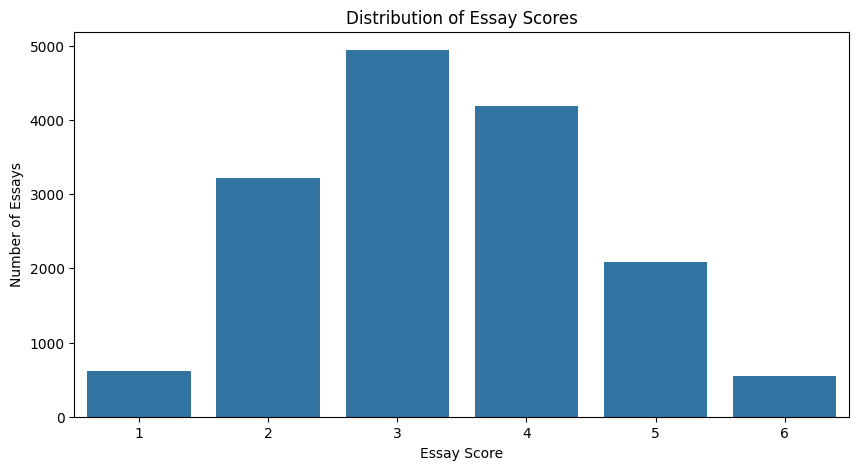

In [ ]:
# Count essays for each score
score_counts = essay_df['holistic_essay_score'].value_counts().sort_index()

print(score_counts)

# Visualize score distribution
plt.figure(figsize=(10, 5))

sns.countplot(
    data=essay_df,
    x='holistic_essay_score'
)

plt.title('Distribution of Essay Scores')
plt.xlabel('Essay Score')
plt.ylabel('Number of Essays')
plt.show()

Average Essay Length: 429.58430064772654
Maximum Essay Length: 14714
Minimum Essay Length: 146


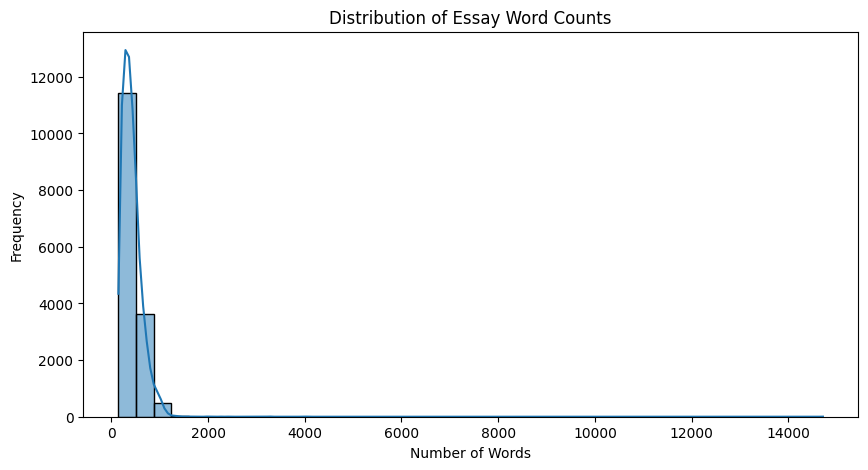

In [ ]:
print("Average Essay Length:",
      essay_df['essay_word_count'].mean())

print("Maximum Essay Length:",
      essay_df['essay_word_count'].max())

print("Minimum Essay Length:",
      essay_df['essay_word_count'].min())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=essay_df,
    x='essay_word_count',
    bins=40,
    kde=True
)

plt.title('Distribution of Essay Word Counts')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')

plt.show()

prompt_name
Does the electoral college work?         1818
Seeking multiple opinions                1544
Distance learning                        1498
Driverless cars                          1386
Facial action coding system              1103
Car-free cities                           983
Exploring Venus                           928
Summer projects                           875
Mandatory extracurricular activities      839
Cell phones at school                     829
The Face on Mars                          819
Grades for extracurricular activities     815
Community service                         768
Phones and driving                        700
"A Cowboy Who Rode the Waves"             688
Name: count, dtype: int64


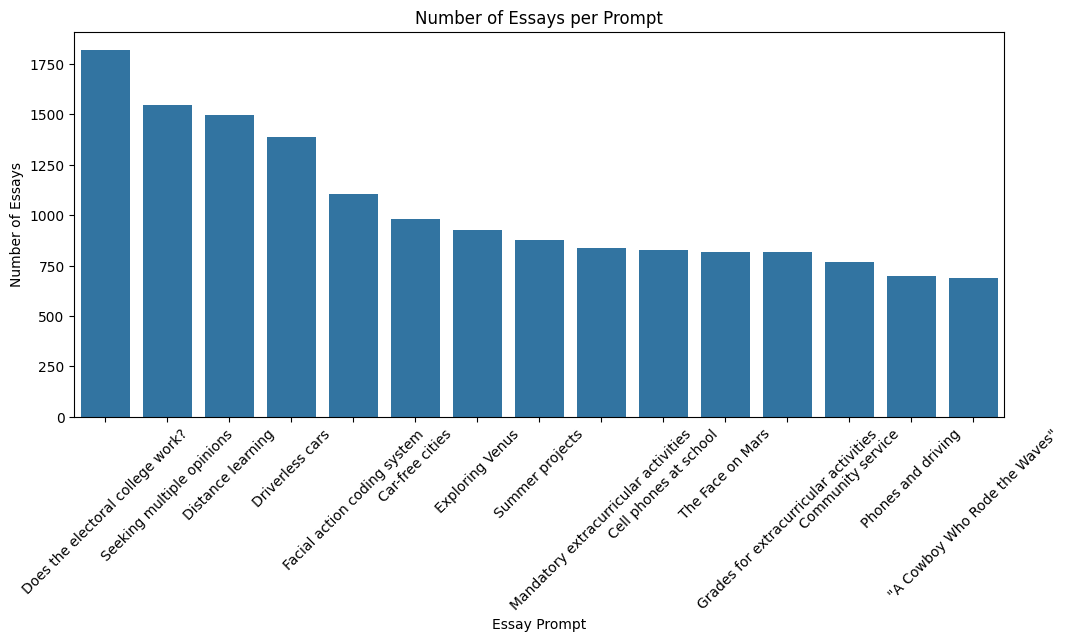

In [ ]:
prompt_counts = essay_df['prompt_name'].value_counts()

print(prompt_counts)

plt.figure(figsize=(12, 5))

sns.countplot(
    data=essay_df,
    x='prompt_name',
    order=prompt_counts.index
)

plt.title('Number of Essays per Prompt')
plt.xlabel('Essay Prompt')
plt.ylabel('Number of Essays')
plt.xticks(rotation=45)

plt.show()

In [ ]:
print("Missing Essay Text:",
      essay_df['full_text'].isnull().sum())

print("Missing Scores:",
      essay_df['holistic_essay_score'].isnull().sum())

print("Empty Essays:",
      (essay_df['full_text'].str.strip() == '').sum())

print("Duplicate Essay IDs:",
      essay_df['essay_id'].duplicated().sum())

Missing Essay Text: 0
Missing Scores: 0
Empty Essays: 0
Duplicate Essay IDs: 0


In [ ]:
essay_df.to_csv(
    '/content/essay_level_dataset.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
import re
import pandas as pd
import numpy as np

print("NLP preprocessing libraries ready!")

NLP preprocessing libraries ready!


In [ ]:
def clean_text(text):

    # Convert text into string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove unwanted special characters
    text = re.sub(r"[^a-z0-9\s']", ' ', text)

    # Remove extra spaces and newlines
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [ ]:
# Create a copy of the dataset
processed_df = essay_df.copy()

# Apply cleaning function
processed_df['cleaned_text'] = processed_df['full_text'].apply(clean_text)

# Display original and cleaned text
print("Original Essay:")
print(processed_df['full_text'].iloc[0][:500])

print("\nCleaned Essay:")
print(processed_df['cleaned_text'].iloc[0][:500])

Original Essay:
Phones

Modern humans today are always on their phone. They are always on their phone more than 5 hours a day no stop .All they do is text back and forward and just have group Chats on social media. They even do it while driving. They are some really bad consequences when stuff happens when it comes to a phone. Some certain areas in the United States ban phones from class rooms just because of it.

When people have phones, they know about certain apps that they have .Apps like Facebook Twitter I

Cleaned Essay:
phones modern humans today are always on their phone they are always on their phone more than 5 hours a day no stop all they do is text back and forward and just have group chats on social media they even do it while driving they are some really bad consequences when stuff happens when it comes to a phone some certain areas in the united states ban phones from class rooms just because of it when people have phones they know about certain apps that they have apps 

In [ ]:
print("Before cleaning:", processed_df.shape)

# Remove empty essays
processed_df = processed_df[
    processed_df['cleaned_text'].str.strip() != ''
].copy()

# Remove missing scores
processed_df = processed_df.dropna(
    subset=['holistic_essay_score']
)

# Remove invalid records
processed_df = processed_df[
    processed_df['holistic_essay_score'].between(1, 6)
].copy()

# Reset index
processed_df.reset_index(drop=True, inplace=True)

print("After cleaning:", processed_df.shape)

Before cleaning: (15593, 6)
After cleaning: (15593, 6)


In [ ]:
processed_df['original_word_count'] = (
    processed_df['full_text'].str.split().str.len()
)

processed_df['cleaned_word_count'] = (
    processed_df['cleaned_text'].str.split().str.len()
)

display(
    processed_df[
        ['original_word_count', 'cleaned_word_count']
    ].head(10)
)

,original_word_count,cleaned_word_count
0,379,379
1,212,212
2,332,332
3,592,596
4,353,356
5,525,527
6,438,439
7,532,535
8,362,389
9,395,398


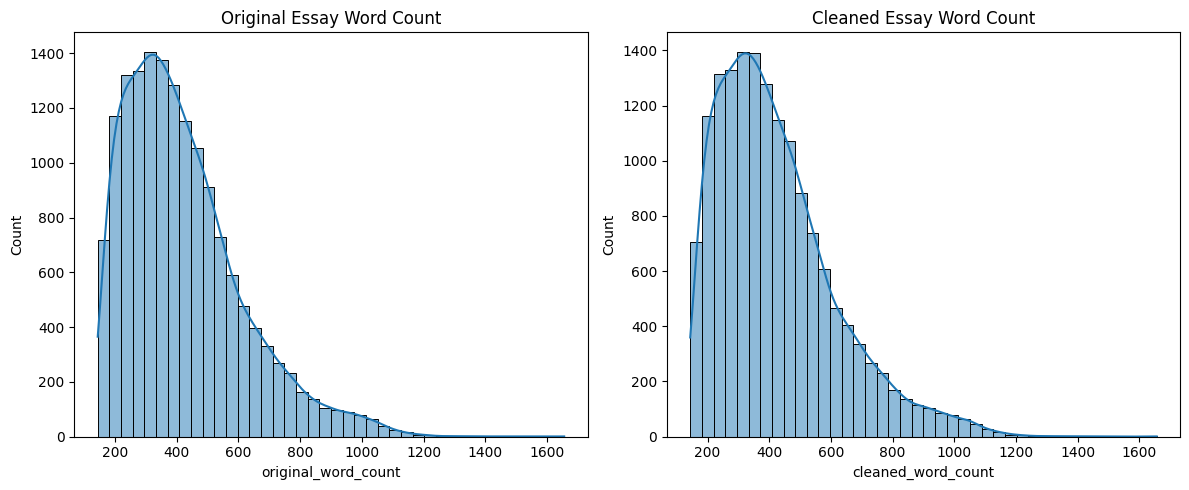

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(
    processed_df['original_word_count'],
    bins=40,
    kde=True
)
plt.title("Original Essay Word Count")

plt.subplot(1, 2, 2)
sns.histplot(
    processed_df['cleaned_word_count'],
    bins=40,
    kde=True
)
plt.title("Cleaned Essay Word Count")

plt.tight_layout()
plt.show()

In [ ]:
# Save preprocessed dataset to Google Drive

output_path = '/content/drive/MyDrive/Colab Notebooks/essay_preprocessed.csv'

processed_df.to_csv(output_path, index=False)

print("Preprocessed dataset saved successfully!")
print("File location:", output_path)
print("Final dataset shape:", processed_df.shape)

Preprocessed dataset saved successfully!
File location: /content/drive/MyDrive/Colab Notebooks/essay_preprocessed.csv
Final dataset shape: (15593, 8)


In [ ]:
from sklearn.model_selection import train_test_split

# Input and target
X = processed_df['cleaned_text']

y = processed_df['holistic_essay_score']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training scores:", y_train.shape)
print("Testing scores:", y_test.shape)

Training data: (12474,)
Testing data: (3119,)
Training scores: (12474,)
Testing scores: (3119,)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Training Shape:", X_train_tfidf.shape)
print("TF-IDF Testing Shape:", X_test_tfidf.shape)

print("Total vocabulary:", len(tfidf.vocabulary_))

TF-IDF Training Shape: (12474, 20000)
TF-IDF Testing Shape: (3119, 20000)
Total vocabulary: 20000


In [ ]:
from sklearn.decomposition import TruncatedSVD

# Initialize SVD
svd = TruncatedSVD(
    n_components=300,
    random_state=42
)

# Fit and transform training data
X_train_svd = svd.fit_transform(X_train_tfidf)

# Transform testing data
X_test_svd = svd.transform(X_test_tfidf)

print("Training SVD Shape:", X_train_svd.shape)
print("Testing SVD Shape:", X_test_svd.shape)

print(
    "Explained Variance Ratio:",
    svd.explained_variance_ratio_.sum()
)

Training SVD Shape: (12474, 300)
Testing SVD Shape: (3119, 300)
Explained Variance Ratio: 0.2823905561005395


In [ ]:
import re
import string
import numpy as np
import pandas as pd

def extract_linguistic_features(text):

    text = str(text)

    # Extract words
    words = re.findall(r'\b[a-zA-Z]+\b', text)

    # Extract sentences
    sentences = re.split(r'[.!?]+', text)
    sentences = [s for s in sentences if s.strip()]

    # Count paragraphs
    paragraphs = [
        p for p in text.split('\n') if p.strip()
    ]

    word_count = len(words)

    sentence_count = max(len(sentences), 1)

    character_count = len(text)

    unique_word_count = len(set(w.lower() for w in words))

    # Average word length
    avg_word_length = (
        np.mean([len(w) for w in words])
        if words else 0
    )

    # Vocabulary richness
    vocabulary_richness = (
        unique_word_count / word_count
        if word_count > 0 else 0
    )

    # Average sentence length
    avg_sentence_length = word_count / sentence_count

    # Punctuation count
    punctuation_count = sum(
        1 for char in text if char in string.punctuation
    )

    # Long words
    long_word_count = sum(
        1 for word in words if len(word) > 6
    )

    paragraph_count = len(paragraphs)

    return [
        word_count,
        sentence_count,
        character_count,
        avg_word_length,
        unique_word_count,
        vocabulary_richness,
        avg_sentence_length,
        punctuation_count,
        long_word_count,
        paragraph_count
    ]

In [ ]:
# Extract original essay texts using the same split indices
X_original = processed_df['full_text']

X_original_train = X_original.loc[X_train.index]
X_original_test = X_original.loc[X_test.index]

# Extract features
X_train_ling = np.array([
    extract_linguistic_features(text)
    for text in X_original_train
])

X_test_ling = np.array([
    extract_linguistic_features(text)
    for text in X_original_test
])

print("Training Linguistic Features:", X_train_ling.shape)
print("Testing Linguistic Features:", X_test_ling.shape)

Training Linguistic Features: (12474, 10)
Testing Linguistic Features: (3119, 10)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data only
X_train_ling_scaled = scaler.fit_transform(X_train_ling)

# Transform test data
X_test_ling_scaled = scaler.transform(X_test_ling)

print("Linguistic features standardized!")

Linguistic features standardized!


In [ ]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(
    n_components=300,
    random_state=42
)

X_train_svd = svd.fit_transform(X_train_tfidf)

X_test_svd = svd.transform(X_test_tfidf)

print("Training SVD Shape:", X_train_svd.shape)
print("Testing SVD Shape:", X_test_svd.shape)

print("Explained Variance:",
      svd.explained_variance_ratio_.sum())

Training SVD Shape: (12474, 300)
Testing SVD Shape: (3119, 300)
Explained Variance: 0.2823905561005395


In [ ]:
# Combine text and linguistic features
X_train_final = np.hstack([
    X_train_svd,
    X_train_ling_scaled
])

X_test_final = np.hstack([
    X_test_svd,
    X_test_ling_scaled
])

print("Final Training Shape:", X_train_final.shape)
print("Final Testing Shape:", X_test_final.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Final Training Shape: (12474, 310)
Final Testing Shape: (3119, 310)
Training Target Shape: (12474,)
Testing Target Shape: (3119,)


In [ ]:
import joblib
import os

# Create project folder
os.makedirs(
    '/content/drive/MyDrive/Colab Notebooks/AEE_Models',
    exist_ok=True
)

model_path = '/content/drive/MyDrive/Colab Notebooks/AEE_Models'

# Save feature extraction objects
joblib.dump(tfidf, model_path + '/tfidf_vectorizer.pkl')
joblib.dump(svd, model_path + '/svd_model.pkl')
joblib.dump(scaler, model_path + '/linguistic_scaler.pkl')

print("Feature extraction objects saved successfully!")

Feature extraction objects saved successfully!


In [ ]:
np.savez_compressed(
    model_path + '/extracted_features.npz',
    X_train=X_train_final,
    X_test=X_test_final,
    y_train=y_train.to_numpy(),
    y_test=y_test.to_numpy()
)

print("Extracted features saved successfully!")

Extracted features saved successfully!


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from scipy.stats import pearsonr

import numpy as np
import pandas as pd
import time

In [ ]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    )
}

print("All models initialized successfully!")

All models initialized successfully!


In [ ]:
results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    # Train model
    model.fit(X_train_final, y_train)

    # Predict scores
    y_pred = model.predict(X_test_final)

    # Evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    pearson_corr, _ = pearsonr(
        y_test, y_pred
    )

    training_time = time.time() - start_time

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2,
        'Pearson Correlation': pearson_corr,
        'Training Time': training_time
    })

    trained_models[name] = model

    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R2 Score: {r2:.4f}")
    print(f"Pearson Correlation: {pearson_corr:.4f}")
    print(f"Training Time: {training_time:.2f} seconds")

print("\nAll models trained successfully!")


Training Linear Regression...
MAE: 0.4497
RMSE: 0.5695
R2 Score: 0.7604
Pearson Correlation: 0.8722
Training Time: 0.57 seconds

Training Ridge Regression...
MAE: 0.4497
RMSE: 0.5699
R2 Score: 0.7600
Pearson Correlation: 0.8720
Training Time: 0.13 seconds

Training Random Forest...
MAE: 0.4415
RMSE: 0.5869
R2 Score: 0.7455
Pearson Correlation: 0.8640
Training Time: 476.60 seconds

Training XGBoost...
MAE: 0.4318
RMSE: 0.5567
R2 Score: 0.7710
Pearson Correlation: 0.8787
Training Time: 42.38 seconds

All models trained successfully!


In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='RMSE',
    ascending=True
)

display(results_df)

,Model,MAE,RMSE,R2 Score,Pearson Correlation,Training Time
3,XGBoost,0.431775,0.556687,0.771006,0.878712,42.381621
0,Linear Regression,0.449728,0.569474,0.760365,0.872177,0.571012
1,Ridge Regression,0.449728,0.569915,0.759994,0.871958,0.132226
2,Random Forest,0.441509,0.586928,0.745450,0.864004,476.601140


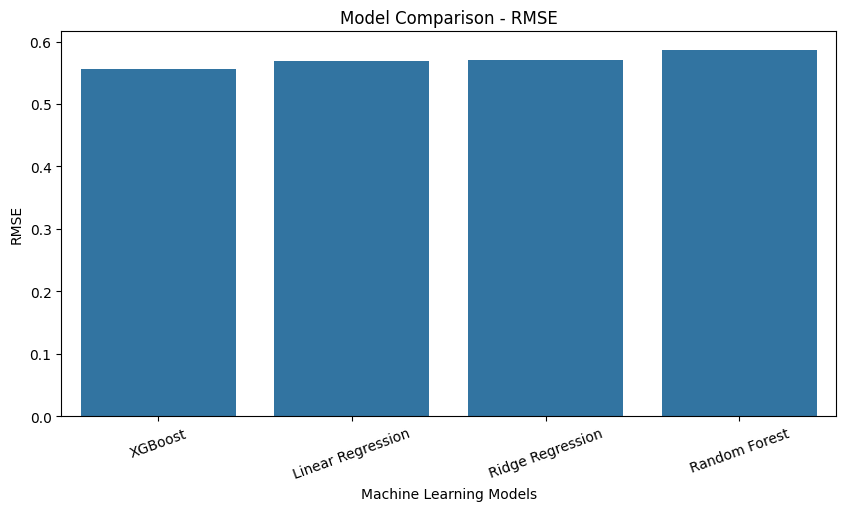

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title('Model Comparison - RMSE')
plt.xlabel('Machine Learning Models')
plt.ylabel('RMSE')
plt.xticks(rotation=20)
plt.show()

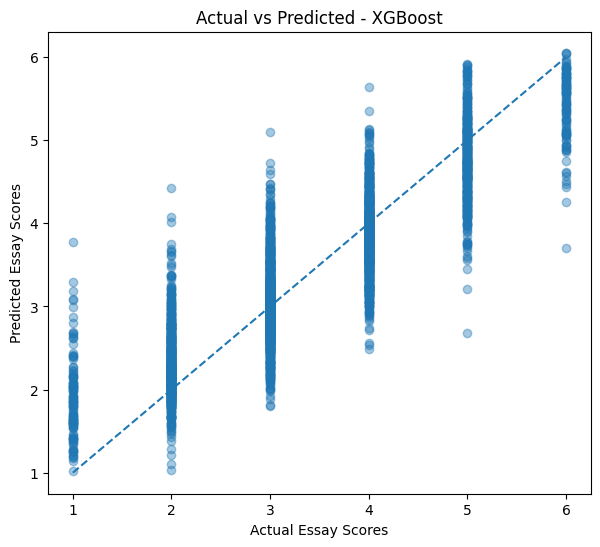

Best Model: XGBoost


In [ ]:
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

y_pred_best = best_model.predict(X_test_final)

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_best,
    alpha=0.4
)

plt.plot(
    [1, 6],
    [1, 6],
    linestyle='--'
)

plt.xlabel("Actual Essay Scores")
plt.ylabel("Predicted Essay Scores")

plt.title(f"Actual vs Predicted - {best_model_name}")

plt.show()

print("Best Model:", best_model_name)

In [ ]:
import joblib
import os

model_path = '/content/drive/MyDrive/Colab Notebooks/AEE_Models'

os.makedirs(model_path, exist_ok=True)

# Save all trained models
for name, model in trained_models.items():

    filename = name.lower().replace(" ", "_") + ".pkl"

    joblib.dump(
        model,
        os.path.join(model_path, filename)
    )

# Save results
results_df.to_csv(
    model_path + '/model_comparison.csv',
    index=False
)

print("All trained models saved successfully!")

All trained models saved successfully!


In [ ]:
# Get XGBoost predictions
y_pred = best_model.predict(X_test_final)

# Convert decimal predictions into integer scores
y_pred_rounded = np.floor(y_pred + 0.5).astype(int)

# Restrict scores between 1 and 6
y_pred_rounded = np.clip(y_pred_rounded, 1, 6)

print("Actual Scores:", y_test.values[:10])
print("Predicted Scores:", y_pred_rounded[:10])

Actual Scores: [2 1 2 4 5 1 4 3 4 3]
Predicted Scores: [2 2 2 5 5 1 4 3 4 4]


In [ ]:
from sklearn.metrics import accuracy_score

# Exact score accuracy
exact_accuracy = accuracy_score(
    y_test,
    y_pred_rounded
)

# Within one score point
within_one_accuracy = np.mean(
    np.abs(y_test.values - y_pred_rounded) <= 1
)

print("Exact Score Accuracy:",
      round(exact_accuracy * 100, 2), "%")

print("Within ±1 Score Accuracy:",
      round(within_one_accuracy * 100, 2), "%")

Exact Score Accuracy: 65.34 %
Within ±1 Score Accuracy: 98.75 %


In [ ]:
comparison_df = pd.DataFrame({
    'Actual Score': y_test.values,
    'Predicted Score': y_pred_rounded,
    'Original Prediction': y_pred
})

display(comparison_df.head(20))

,Actual Score,Predicted Score,Original Prediction
0,2,2,2.458537
1,1,2,1.544658
2,2,2,2.284418
3,4,5,4.620125
4,5,5,4.722648
5,1,1,1.191789
6,4,4,3.886559
7,3,3,3.151185
8,4,4,4.049520
9,3,4,4.059173


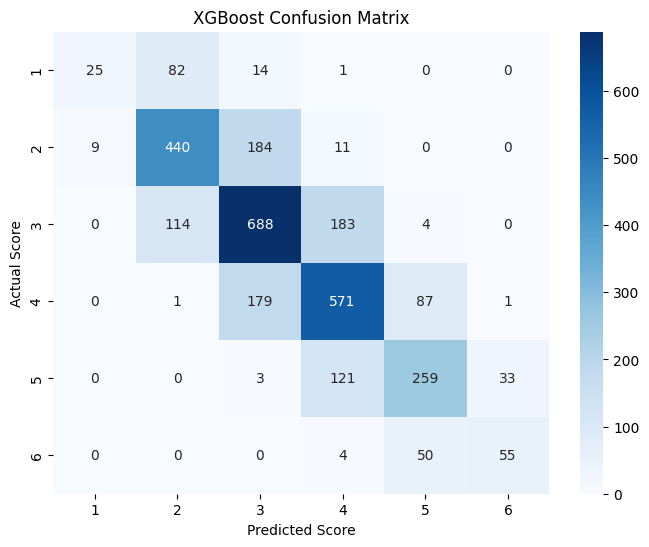

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_rounded,
    labels=[1, 2, 3, 4, 5, 6]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[1, 2, 3, 4, 5, 6],
    yticklabels=[1, 2, 3, 4, 5, 6]
)

plt.xlabel("Predicted Score")
plt.ylabel("Actual Score")
plt.title("XGBoost Confusion Matrix")

plt.show()

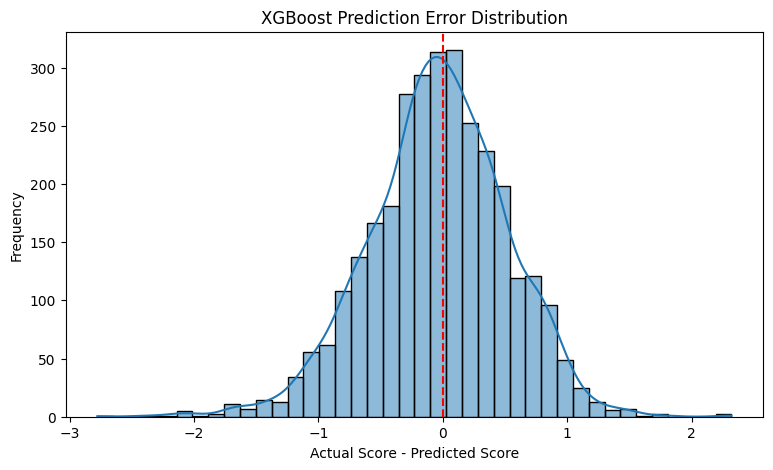

In [ ]:
# Calculate prediction errors
errors = y_test.values - y_pred

plt.figure(figsize=(9, 5))

sns.histplot(
    errors,
    bins=40,
    kde=True
)

plt.axvline(
    0,
    linestyle='--',
    color='red'
)

plt.title("XGBoost Prediction Error Distribution")
plt.xlabel("Actual Score - Predicted Score")
plt.ylabel("Frequency")

plt.show()

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
from scipy.stats import randint, uniform
import time

In [ ]:
param_dist = {
    'n_estimators': [200, 300, 400, 500, 600],

    'learning_rate': [0.01, 0.03, 0.05, 0.07, 0.1],

    'max_depth': [3, 4, 5, 6, 7],

    'min_child_weight': [1, 3, 5, 7],

    'subsample': [0.7, 0.8, 0.9, 1.0],

    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],

    'gamma': [0, 0.1, 0.2, 0.3]
}

In [ ]:
xgb_base = XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    n_jobs=2
)

random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_dist,
    n_iter=10,
    scoring='neg_root_mean_squared_error',
    cv=3,
    random_state=42,
    verbose=2,
    n_jobs=1
)

print("Hyperparameter search initialized!")

Hyperparameter search initialized!


In [ ]:
start_time = time.time()

random_search.fit(
    X_train_final,
    y_train
)

tuning_time = time.time() - start_time

print("Hyperparameter tuning completed!")

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross Validation RMSE:")
print(-random_search.best_score_)

print("\nTuning Time:", round(tuning_time, 2), "seconds")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END colsample_bytree=0.9, gamma=0.3, learning_rate=0.1, max_depth=3, min_child_weight=5, n_estimators=500, subsample=0.9; total time=  32.3s
[CV] END colsample_bytree=0.9, gamma=0.3, learning_rate=0.1, max_depth=3, min_child_weight=5, n_estimators=500, subsample=0.9; total time=  12.9s
[CV] END colsample_bytree=0.9, gamma=0.3, learning_rate=0.1, max_depth=3, min_child_weight=5, n_estimators=500, subsample=0.9; total time=  14.1s
[CV] END colsample_bytree=0.8, gamma=0.3, learning_rate=0.1, max_depth=5, min_child_weight=3, n_estimators=500, subsample=1.0; total time=  20.4s
[CV] END colsample_bytree=0.8, gamma=0.3, learning_rate=0.1, max_depth=5, min_child_weight=3, n_estimators=500, subsample=1.0; total time=  19.2s
[CV] END colsample_bytree=0.8, gamma=0.3, learning_rate=0.1, max_depth=5, min_child_weight=3, n_estimators=500, subsample=1.0; total time=  17.3s
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.05, max

In [ ]:
best_xgb = random_search.best_estimator_

# Predict test scores
y_pred_tuned = best_xgb.predict(X_test_final)

# Calculate metrics
tuned_mae = mean_absolute_error(
    y_test,
    y_pred_tuned
)

tuned_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_tuned)
)

tuned_r2 = r2_score(
    y_test,
    y_pred_tuned
)

tuned_corr, _ = pearsonr(
    y_test,
    y_pred_tuned
)

print("TUNED XGBOOST RESULTS")

print("MAE:", round(tuned_mae, 4))
print("RMSE:", round(tuned_rmse, 4))
print("R2 Score:", round(tuned_r2, 4))
print("Pearson Correlation:", round(tuned_corr, 4))

TUNED XGBOOST RESULTS
MAE: 0.4321
RMSE: 0.5552
R2 Score: 0.7723
Pearson Correlation: 0.8792


In [ ]:
comparison = pd.DataFrame({
    'Model': [
        'Original XGBoost',
        'Tuned XGBoost'
    ],

    'MAE': [
        0.431775,
        tuned_mae
    ],

    'RMSE': [
        0.556687,
        tuned_rmse
    ],

    'R2 Score': [
        0.771006,
        tuned_r2
    ],

    'Pearson Correlation': [
        0.878712,
        tuned_corr
    ]
})

display(comparison)

,Model,MAE,RMSE,R2 Score,Pearson Correlation
0,Original XGBoost,0.431775,0.556687,0.771006,0.878712
1,Tuned XGBoost,0.432084,0.555162,0.772258,0.879169


In [ ]:
y_pred_tuned_rounded = np.clip(
    np.floor(y_pred_tuned + 0.5).astype(int),
    1,
    6
)

tuned_exact_accuracy = accuracy_score(
    y_test,
    y_pred_tuned_rounded
)

tuned_within_one = np.mean(
    np.abs(y_test.values - y_pred_tuned_rounded) <= 1
)

print(
    "Tuned Exact Accuracy:",
    round(tuned_exact_accuracy * 100, 2), "%"
)

print(
    "Tuned Within ±1 Accuracy:",
    round(tuned_within_one * 100, 2), "%"
)

Tuned Exact Accuracy: 65.21 %
Tuned Within ±1 Accuracy: 98.72 %
